In [1]:
import pandas as pd

df_ips = pd.read_csv('../donnees/fr-en-ips_lycees.csv', sep=';')

/Users/alexis/opt/anaconda3/lib/python3.8/site-packages/pandas/core/computation/expressions.py:20: UserWarning: Pandas requires version '2.7.3' or newer of 'numexpr' (version '2.7.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [2]:
df_ips.head()

,Rentrée scolaire,Académie,Code du département,Département,UAI,Nom de l'établissment,Code INSEE de la commune,Nom de la commune,Secteur,Type de lycée,IPS voie GT,IPS voie PRO,IPS Ensemble GT-PRO,Ecart-type de l'IPS voie GT,Ecart-type de l'IPS voie PRO
0,2016-2017,LYON,1.0,AIN,0010010F,LYCEE GENERAL ET TECHNOLOGIQUE DU BUGEY,1034.0,BELLEY,public,LEGT,109.5,NaN,109.5,NaN,NaN
1,2016-2017,LYON,1.0,AIN,0010034G,LYCEE POLYVALENT PAUL PAINLEVE,1283.0,OYONNAX,public,LPO,92.2,73.4,86.5,NaN,NaN
2,2016-2017,LYON,1.0,AIN,0010070W,LYCEE GENERAL ET TECHNOLOGIQUE PRIVE SAINT PIERRE,1053.0,BOURG EN BRESSE,privé sous contrat,LEGT,126.5,NaN,126.5,NaN,NaN
3,2016-2017,LYON,1.0,AIN,0010075B,LYCEE GENERAL ET TECHNOLOGIQUE PRIVE SAINT JOSEPH,1249.0,MIRIBEL,privé sous contrat,LEGT,120.7,NaN,120.7,NaN,NaN
4,2016-2017,LYON,1.0,AIN,0011010T,LYCEE PROFESSIONNEL DU BUGEY,1034.0,BELLEY,public,LP,NaN,84.6,84.6,NaN,NaN


In [5]:
df_ips["Année"] = df_ips["Rentrée scolaire"].str[-4:].astype(int)

In [10]:
df_ips.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21777 entries, 0 to 21776
Data columns (total 15 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Rentrée scolaire              21777 non-null  object 
 1   Académie                      21777 non-null  object 
 2   Code du département           21687 non-null  float64
 3   Département                   21777 non-null  object 
 4   UAI                           21777 non-null  object 
 5   Nom de l'établissment         21777 non-null  object 
 6   Code INSEE de la commune      21687 non-null  float64
 7   Nom de la commune             21777 non-null  object 
 8   Secteur                       21777 non-null  object 
 9   Type de lycée                 21777 non-null  object 
 10  IPS voie GT                   14792 non-null  float64
 11  IPS voie PRO                  12556 non-null  float64
 12  IPS Ensemble GT-PRO           21777 non-null  float64
 13  E

In [13]:
print(len(df_ips['Ecart-type de l\'IPS voie PRO'].isna()))

21777


In [12]:
print(len(df_ips))

21777


In [2]:
df_res = pd.read_csv('../donnees/fr-en-indicateurs-de-resultat-des-lycees-gt_v2.csv', sep=';')

In [15]:
df_res.head()

,Année,UAI,Etablissement,Secteur,Code commune,Commune,Code departement,Département,Académie,Code région,...,Valeur ajoutée du taux de mentions - S2TMD,Valeur ajoutée du taux de mentions - STHR,Nombre de mentions TB avec félicitations - G,Nombre de mentions TB sans félicitations - G,Nombre de mentions B - G,Nombre de mentions AB - G,Nombre de mentions TB avec félicitations - T,Nombre de mentions TB sans félicitations - T,Nombre de mentions B - T,Nombre de mentions AB - T
0,2025,0511135G,LYCEE NOTRE-DAME ST VICTOR,privé sous contrat,51230,EPERNAY,51,MARNE,REIMS,44,...,NaN,NaN,NaN,10.0,20.0,38.0,NaN,NaN,NaN,NaN
1,2025,0511145T,LYCEE ST MICHEL (GENERAL ET TECHNO.),privé sous contrat,51454,REIMS,51,MARNE,REIMS,44,...,NaN,NaN,NaN,3.0,18.0,19.0,NaN,1.0,4.0,17.0
2,2025,0530004S,LYCEE VICTOR HUGO,public,53062,CHATEAU GONTIER SUR MAYENNE,53,MAYENNE,NANTES,52,...,NaN,NaN,NaN,11.0,43.0,49.0,NaN,1.0,5.0,11.0
3,2025,0530010Y,LYCEE AMBROISE PARE,public,53130,LAVAL,53,MAYENNE,NANTES,52,...,NaN,NaN,2.0,21.0,58.0,81.0,NaN,NaN,7.0,23.0
4,2025,0530016E,LYCEE LAVOISIER,public,53147,MAYENNE,53,MAYENNE,NANTES,52,...,NaN,NaN,NaN,12.0,33.0,47.0,NaN,NaN,2.0,10.0


In [16]:
df_res.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32485 entries, 0 to 32484
Data columns (total 88 columns):
 #   Column                                              Non-Null Count  Dtype  
---  ------                                              --------------  -----  
 0   Année                                               32485 non-null  int64  
 1   UAI                                                 32485 non-null  object 
 2   Etablissement                                       32485 non-null  object 
 3   Secteur                                             32485 non-null  object 
 4   Code commune                                        32485 non-null  object 
 5   Commune                                             32485 non-null  object 
 6   Code departement                                    32485 non-null  object 
 7   Département                                         32485 non-null  object 
 8   Académie                                            32485 non-null  object 


In [7]:
df = pd.merge(df_ips, df_res, how='inner', on=["UAI", "Année"])

In [18]:
df.head()

,Rentrée scolaire,Académie_x,Code du département,Département_x,UAI,Nom de l'établissment,Code INSEE de la commune,Nom de la commune,Secteur_x,Type de lycée,...,Valeur ajoutée du taux de mentions - S2TMD,Valeur ajoutée du taux de mentions - STHR,Nombre de mentions TB avec félicitations - G,Nombre de mentions TB sans félicitations - G,Nombre de mentions B - G,Nombre de mentions AB - G,Nombre de mentions TB avec félicitations - T,Nombre de mentions TB sans félicitations - T,Nombre de mentions B - T,Nombre de mentions AB - T
0,2016-2017,LYON,1.0,AIN,0010010F,LYCEE GENERAL ET TECHNOLOGIQUE DU BUGEY,1034.0,BELLEY,public,LEGT,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2016-2017,LYON,1.0,AIN,0010010F,LYCEE GENERAL ET TECHNOLOGIQUE DU BUGEY,1034.0,BELLEY,public,LEGT,...,NaN,NaN,2.0,15.0,25.0,44.0,NaN,1.0,4.0,20.0
2,2016-2017,LYON,1.0,AIN,0010010F,LYCEE GENERAL ET TECHNOLOGIQUE DU BUGEY,1034.0,BELLEY,public,LEGT,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2016-2017,LYON,1.0,AIN,0010010F,LYCEE GENERAL ET TECHNOLOGIQUE DU BUGEY,1034.0,BELLEY,public,LEGT,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2016-2017,LYON,1.0,AIN,0010010F,LYCEE GENERAL ET TECHNOLOGIQUE DU BUGEY,1034.0,BELLEY,public,LEGT,...,NaN,NaN,4.0,20.0,33.0,45.0,NaN,NaN,5.0,11.0


In [27]:
df.columns.to_list()

['Rentrée scolaire',
 'Académie_x',
 'Code du département',
 'Département_x',
 'UAI',
 "Nom de l'établissment",
 'Code INSEE de la commune',
 'Nom de la commune',
 'Secteur_x',
 'Type de lycée',
 'IPS voie GT',
 'IPS voie PRO',
 'IPS Ensemble GT-PRO',
 "Ecart-type de l'IPS voie GT",
 "Ecart-type de l'IPS voie PRO",
 'Année',
 'Etablissement',
 'Secteur_y',
 'Code commune',
 'Commune',
 'Code departement',
 'Département_y',
 'Académie_y',
 'Code région',
 'Region',
 'Présents - Toutes séries',
 'Taux de réussite - Toutes séries',
 'Valeur ajoutée du taux de réussite - Toutes séries',
 "Taux d'accès 2nde-bac",
 "Valeur ajoutée du taux d'acces 2nde-bac",
 'Taux de mentions - Toutes séries',
 'Valeur ajoutée du taux de mentions - Toutes séries',
 'Présents - L',
 'Présents - ES',
 'Présents - S',
 'Présents - Gnle',
 'Présents - STI2D',
 'Présents - STD2A',
 'Présents - STMG',
 'Présents - STL',
 'Présents - ST2S',
 'Présents - S2TMD',
 'Présents - STHR',
 'Taux de réussite - L',
 'Taux de

In [8]:
import seaborn as sns 

In [28]:
import matplotlib.pyplot as plt

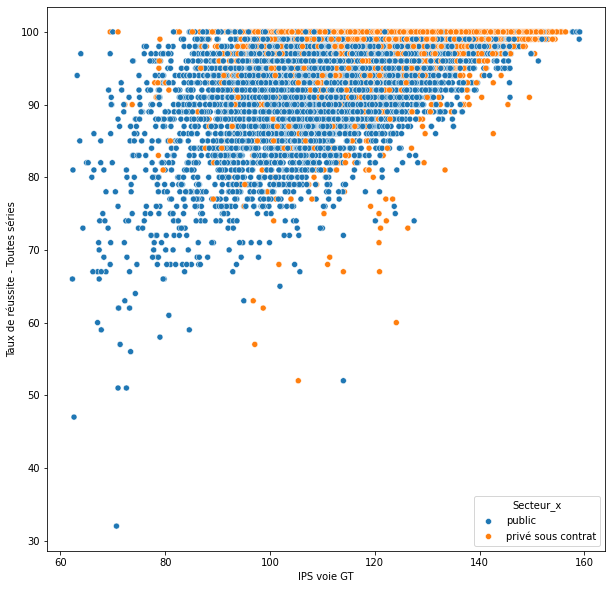

In [ ]:
plt.figure(figsize=(10,10))
ax = sns.scatterplot(data=df, x="IPS voie GT", y = "Taux de réussite - Toutes séries", hue="Secteur_x")

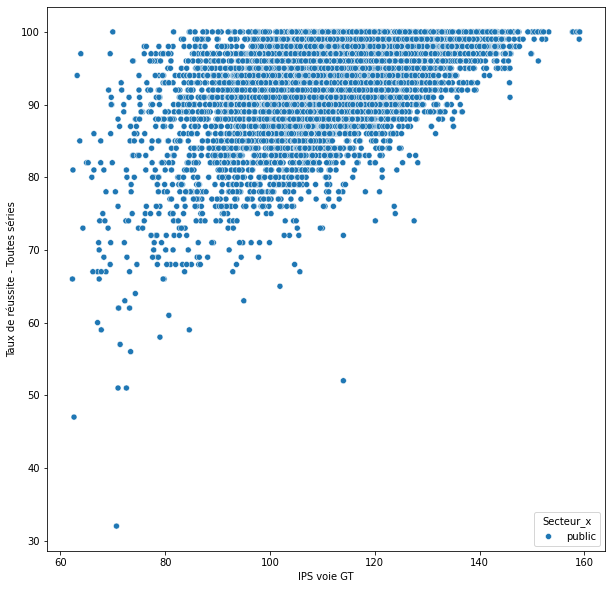

In [32]:
plt.figure(figsize=(10,10))
ax = sns.scatterplot(data=df[df["Secteur_x"] == "public"], x="IPS voie GT", y = "Taux de réussite - Toutes séries", hue="Secteur_x")

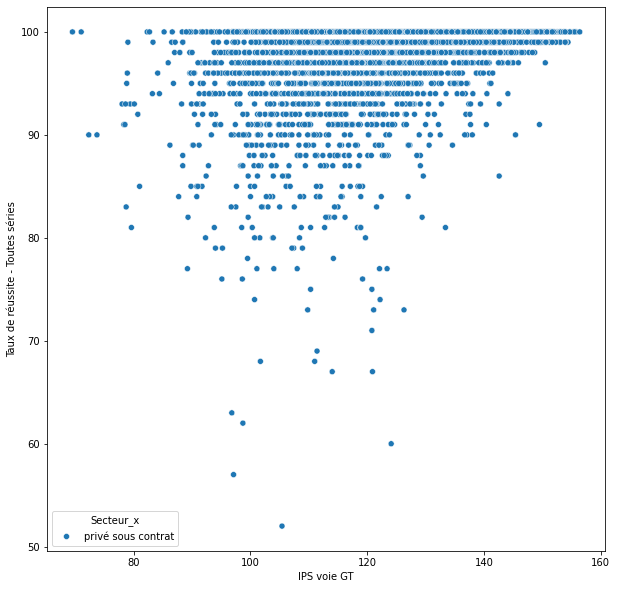

In [33]:
plt.figure(figsize=(10,10))
ax = sns.scatterplot(data=df[df["Secteur_x"] == "privé sous contrat"], x="IPS voie GT", y = "Taux de réussite - Toutes séries", hue="Secteur_x")

   IPS voie GT  Taux de réussite - Toutes séries  count
0        109.5                              84.0      1
1         92.2                              83.0      1
4        106.5                              92.0      1
5        102.7                              80.0      1
6        112.1                              90.0      1


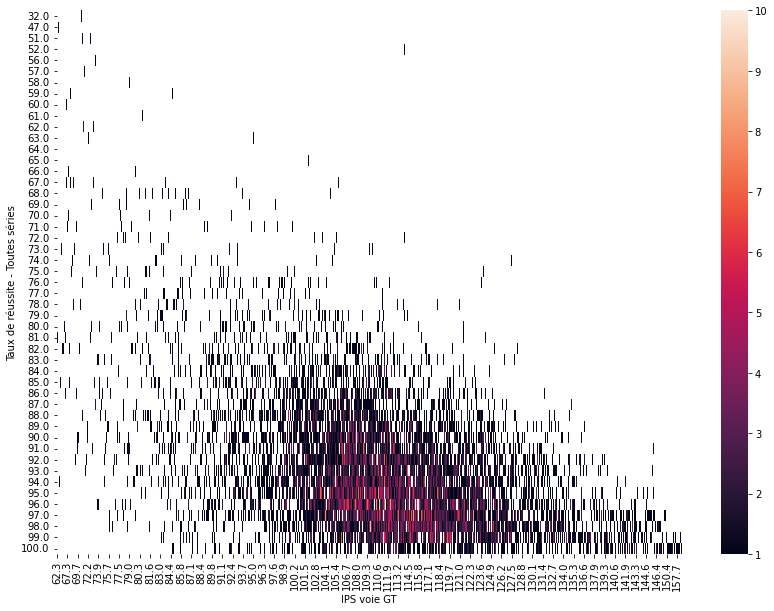

In [48]:
heat_data = df[df["Secteur_x"] == "public"][["IPS voie GT","Taux de réussite - Toutes séries"]]
heat_data["count"] = 1
print(heat_data.head())
heat_data = heat_data.groupby(["IPS voie GT", "Taux de réussite - Toutes séries"]).agg({"count": "sum"})
heat_data = heat_data.pivot_table(index = "Taux de réussite - Toutes séries", columns = "IPS voie GT", values = "count", aggfunc="sum")

plt.figure(figsize=(14,10))
ax = sns.heatmap(data=heat_data)

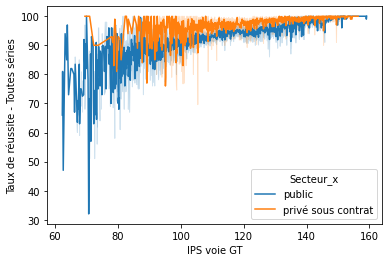

In [24]:
ax = sns.lineplot(data=df, x="IPS voie GT", y = "Taux de réussite - Toutes séries",hue="Secteur_x")


<Axes: xlabel='Secteur', ylabel='IPS voie GT'>

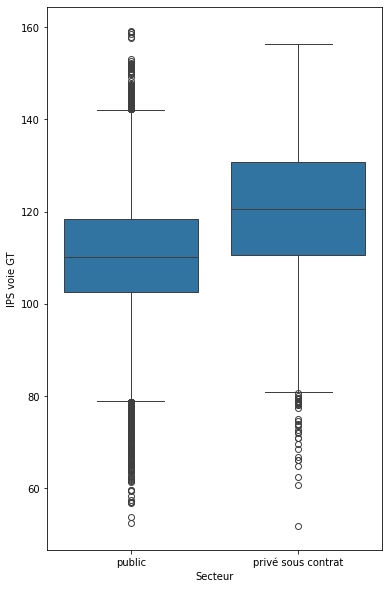

In [49]:
plt.figure(figsize=(6,10))
sns.boxplot(data=df_ips, x="Secteur", y = "IPS voie GT")